## __Demanda de OD vs Agentes__

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import linregress
import os

pd.options.display.float_format = '{:,.2f}'.format

### 1. Preparar Matrices

In [9]:
def prepare_demand_od(df):
    od = df[
        ["Origen_ageb", "Destino_ageb", "Ponderador_x_PF"]
    ].copy()

    od.columns = ["Origin", "Destination", "Demand_OD"]
    od = (
        od.groupby(["Origin", "Destination"], as_index=False)
        ["Demand_OD"].sum()
    )
    return od

def prepare_demand_agents(df):
    df.rename(columns={"Data": "Demand_Agents"}, inplace=True)
    df = (
        df.groupby(["Origin", "Destination"], as_index=False)
        ["Demand_Agents"].sum()
    )
    return df

### 2. Calcular diferencias entre demanda

In [3]:
def compare_demand(od, agents):
    demand = pd.merge(
        od, 
        agents, 
        on=["Origin", "Destination"], 
        how="outer"
    )
    demand.fillna(0, inplace=True)

    demand["Difference"] = (
        demand["Demand_Agents"] - demand["Demand_OD"]
    )
    demand["Abs_Difference"] = demand["Difference"].abs()

    demand["OD_Status"] = np.select(
        [
            (demand["Demand_OD"] > 0) &
            (demand["Demand_Agents"] > 0),

            (demand["Demand_OD"] > 0) &
            (demand["Demand_Agents"] == 0),

            (demand["Demand_OD"] == 0) &
            (demand["Demand_Agents"] > 0)
        ],
        ["Both", "Only_OD", "Only_Agents"],
        default="Zero"
    )

    return demand

### 3. Calcular indicadores

In [15]:
def calculate_metrics(df):

    x = df["Demand_OD"].to_numpy()
    y = df["Demand_Agents"].to_numpy()

    total_od = x.sum()
    total_toronto = y.sum()

    valid = (
        len(df) >= 2
        and np.std(x) > 0
        and np.std(y) > 0
    )

    if valid:
        regression = linregress(x, y)
        r2_regression = regression.rvalue ** 2
        slope = regression.slope
        intercept = regression.intercept
    else:
        r2_regression = np.nan
        slope = np.nan
        intercept = np.nan

    metrics = {
        "Total_OD": total_od,
        "Total_Agents": total_toronto,

        "Difference": total_toronto - total_od,

        "Pct_Difference": (
            (total_toronto - total_od) / total_od * 100
            if total_od > 0 else np.nan
        ),

        "R2_regression": r2_regression,

        "R2_identity": (
            r2_score(x, y)
            if len(df) >= 2 and np.var(x) > 0
            else np.nan
        ),

        "Slope": slope,
        "Intercept": intercept,

        "MAE": mean_absolute_error(x, y),

        "WAPE": (
            np.abs(y - x).sum() / total_od * 100
            if total_od > 0 else np.nan
        ),

        "OD_Pairs": len(df),

        "Only_OD": (df["OD_Status"] == "Only_OD").sum(),
        "Only_Toronto": (df["OD_Status"] == "Only_Toronto").sum()
    }

    return pd.Series(metrics)

### 4. Graficar

In [25]:
def plot_od_scatter(df, ax, title="OD vs Toronto"):

    x = df["Demand_OD"]
    y = df["Demand_Agents"]

    metrics = calculate_metrics(df)

    ax.scatter(x, y, alpha=0.35, s=8)

    max_val = max(x.max(), y.max())

    ax.plot(
        [0, max_val],
        [0, max_val],
        linestyle="--",
        color="red"
    )

    ax.set_xlabel("Original OD Demand")
    ax.set_ylabel("Toronto Agent Demand")
    ax.set_title(title)

    ax.text(
        0.05, 0.95,
        f"R² = {metrics['R2_regression']:.3f}\n"
        f"Diff = {metrics['Pct_Difference']:.1f}%\n"
        f"WAPE = {metrics['WAPE']:.1f}%",
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85)
    )

    ax.grid(alpha=0.2)

In [28]:
OD_DEMAND_FOLDER = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Matriz Origen Destino/Matrices Demanda por periodo y modo'
AGENTS_DEMAND_FOLDER = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Demand'

matrix_files = {
    "EM": {
        "AUTO": (
            "matriz_VP_EM.csv",
            "AutoEM.mtx.csv"
        ),
        "TRANSIT": (
            "matriz_TP_EM.csv",
            "TransitEM.mtx.csv"
        )
    },
    "AP": {
        "AUTO": (
            "matriz_VP_AP.csv",
            "AutoAP.mtx.csv"
        ),
        "LIGHT_FREIGHT": (
            "matriz_LIGHT_FREIGHT_AP.csv",
            "APTruckLight_pcu_ph.mtx.csv"
        ),
        "HEAVY_FREIGHT": (
            "matriz_HEAVY_FREIGHT_AP.csv",
            "APTruckHeavy_pcu_ph.mtx.csv"
        ),
        "TRANSIT": (
            "matriz_TP_AP.csv",
            "TransitAP.mtx.csv"
        )
    },
    "LM": {
        "AUTO": (
            "matriz_VP_LM.csv",
            "AutoLM.mtx.csv"
        ),
        "LIGHT_FREIGHT": (
            "matriz_LIGHT_FREIGHT_LM.csv",
            "LMTruckLight_pcu_ph.mtx.csv"
        ),
        "HEAVY_FREIGHT": (
            "matriz_HEAVY_FREIGHT_LM.csv",
            "LMTruckHeavy_pcu_ph.mtx.csv"
        ),
        "TRANSIT": (
            "matriz_TP_LM.csv",
            "TransitLM.mtx.csv"
        )
    },
    "EA": {
        "AUTO": (
            "matriz_VP_EA.csv",
            "AutoEA.mtx.csv"
        ),
        "LIGHT_FREIGHT": (
            "matriz_LIGHT_FREIGHT_EA.csv",
            "EATruckLight_pcu_ph.mtx.csv"
        ),
        "HEAVY_FREIGHT": (
            "matriz_HEAVY_FREIGHT_EA.csv",
            "EATruckHeavy_pcu_ph.mtx.csv"
        ),
        "TRANSIT": (
            "matriz_TP_EA.csv",
            "TransitEA.mtx.csv"
        )
    },
    "PP": {
        "AUTO": (
            "matriz_VP_PP.csv",
            "AutoPP.mtx.csv"
        ),
        "LIGHT_FREIGHT": (
            "matriz_LIGHT_FREIGHT_PP.csv",
            "PPTruckLight_pcu_ph.mtx.csv"
        ),
        "HEAVY_FREIGHT": (
            "matriz_HEAVY_FREIGHT_PP.csv",
            "PPTruckHeavy_pcu_ph.mtx.csv"
        ),
        "TRANSIT": (
            "matriz_TP_PP.csv",
            "TransitPP.mtx.csv"
        )
    },
    "LN": {
        "AUTO": (
            "matriz_VP_LN.csv",
            "AutoLN.mtx.csv"
        ),
        "TRANSIT": (
            "matriz_TP_LN.csv",
            "TransitLN.mtx.csv"
        )
    },
}

Processing EM - AUTO
Processing EM - TRANSIT


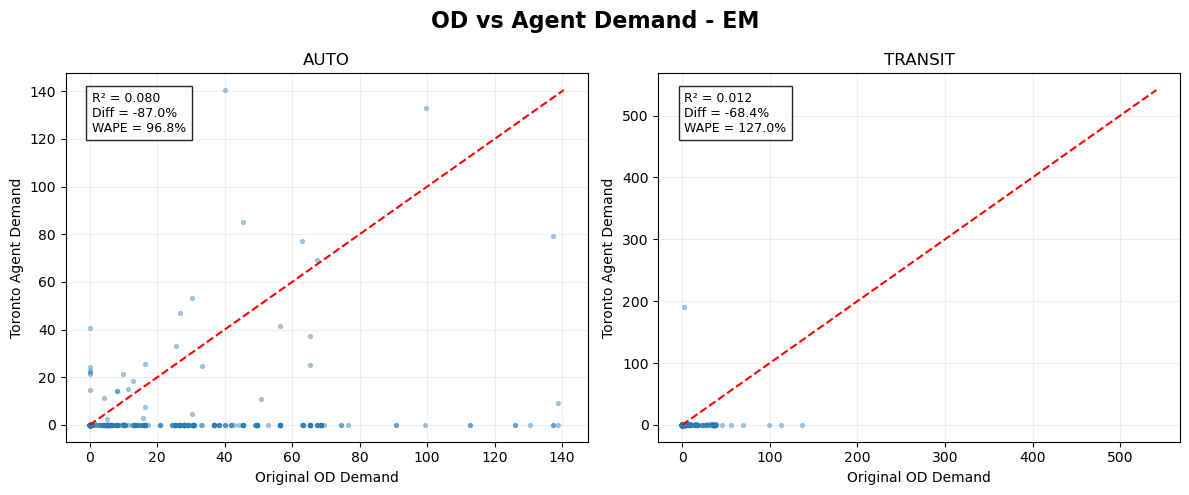

Processing AP - AUTO
Processing AP - LIGHT_FREIGHT
Processing AP - HEAVY_FREIGHT
Processing AP - TRANSIT


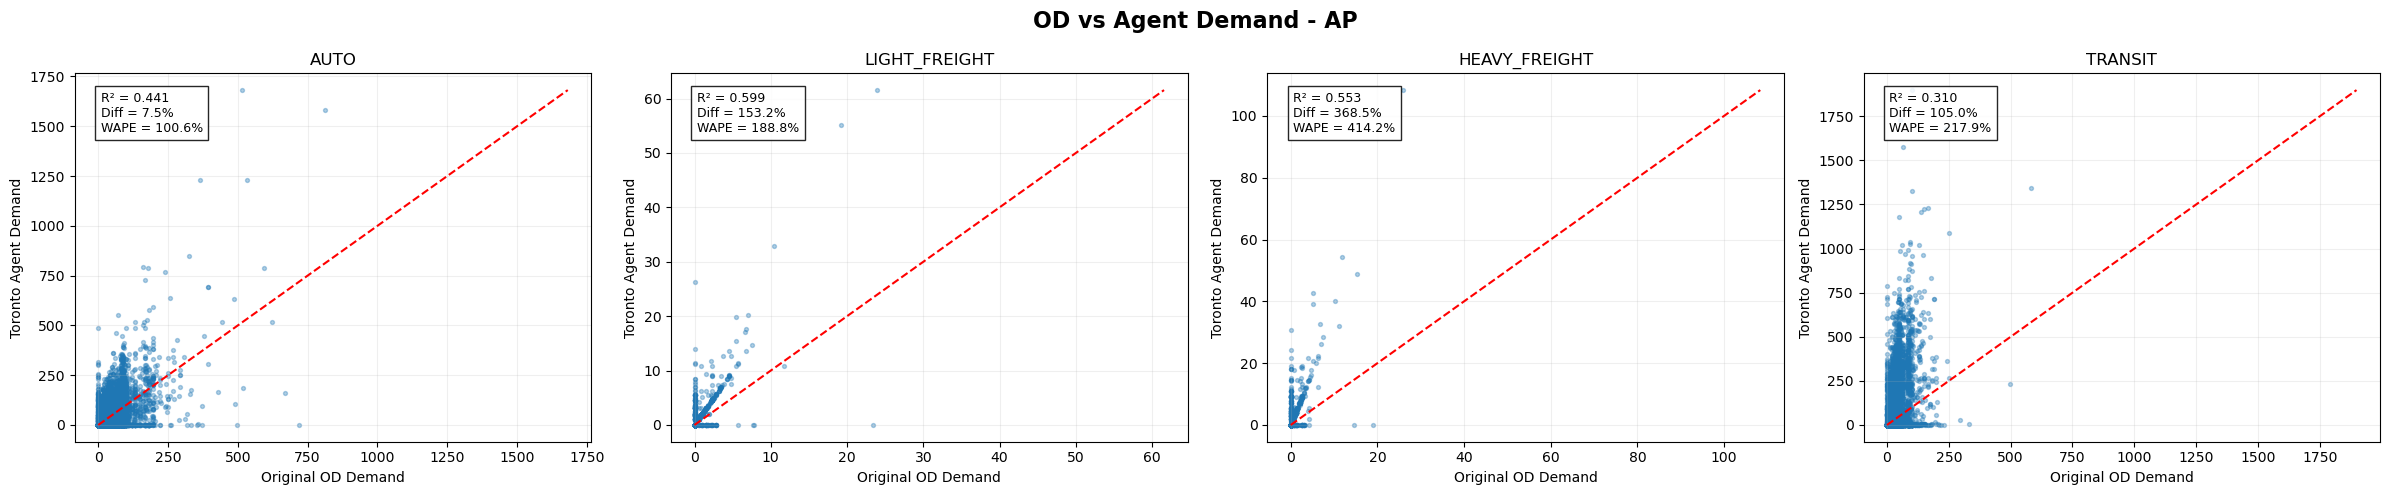

Processing LM - AUTO
Processing LM - LIGHT_FREIGHT
Processing LM - HEAVY_FREIGHT
Processing LM - TRANSIT


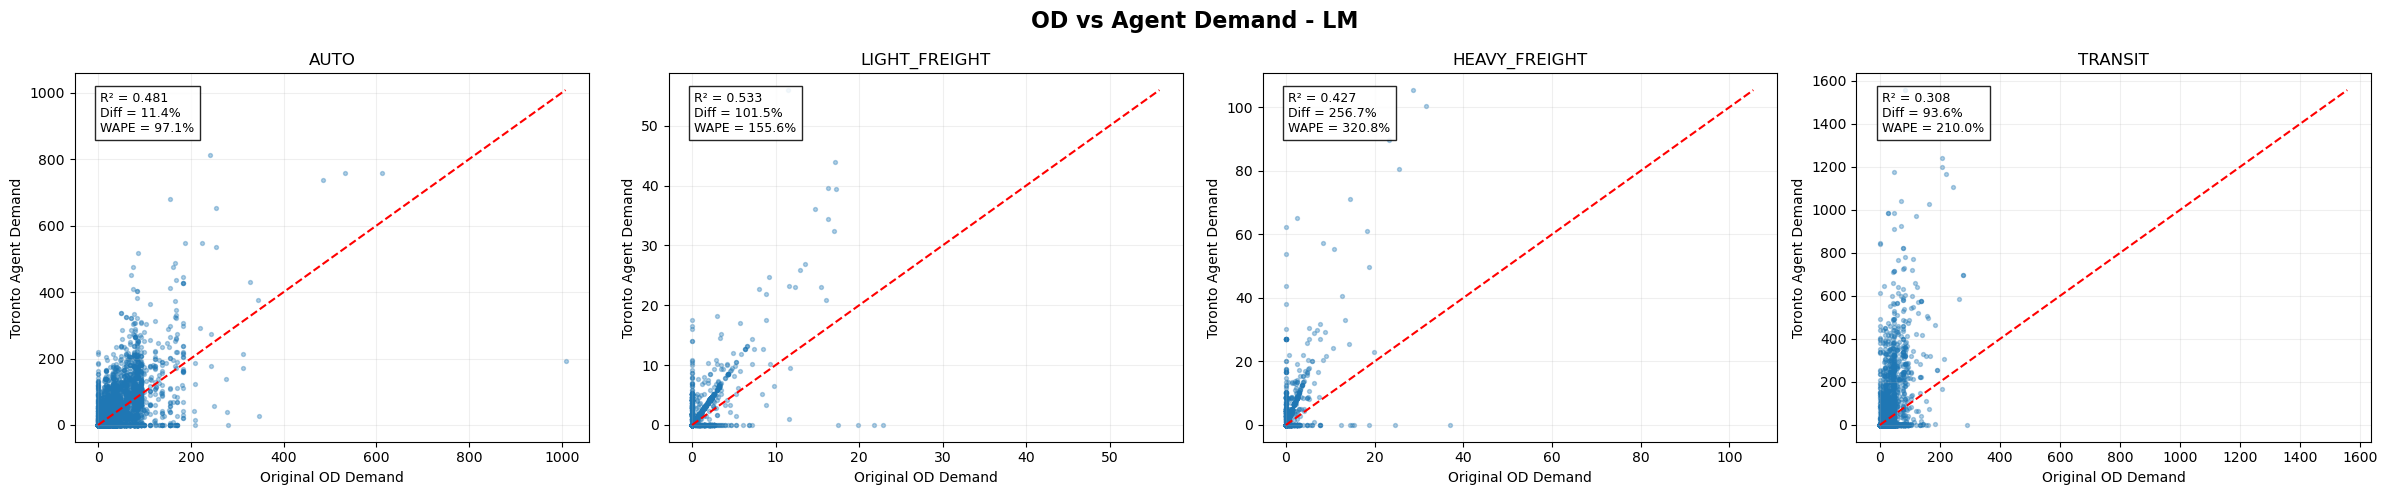

Processing EA - AUTO
Processing EA - LIGHT_FREIGHT
Processing EA - HEAVY_FREIGHT
Processing EA - TRANSIT


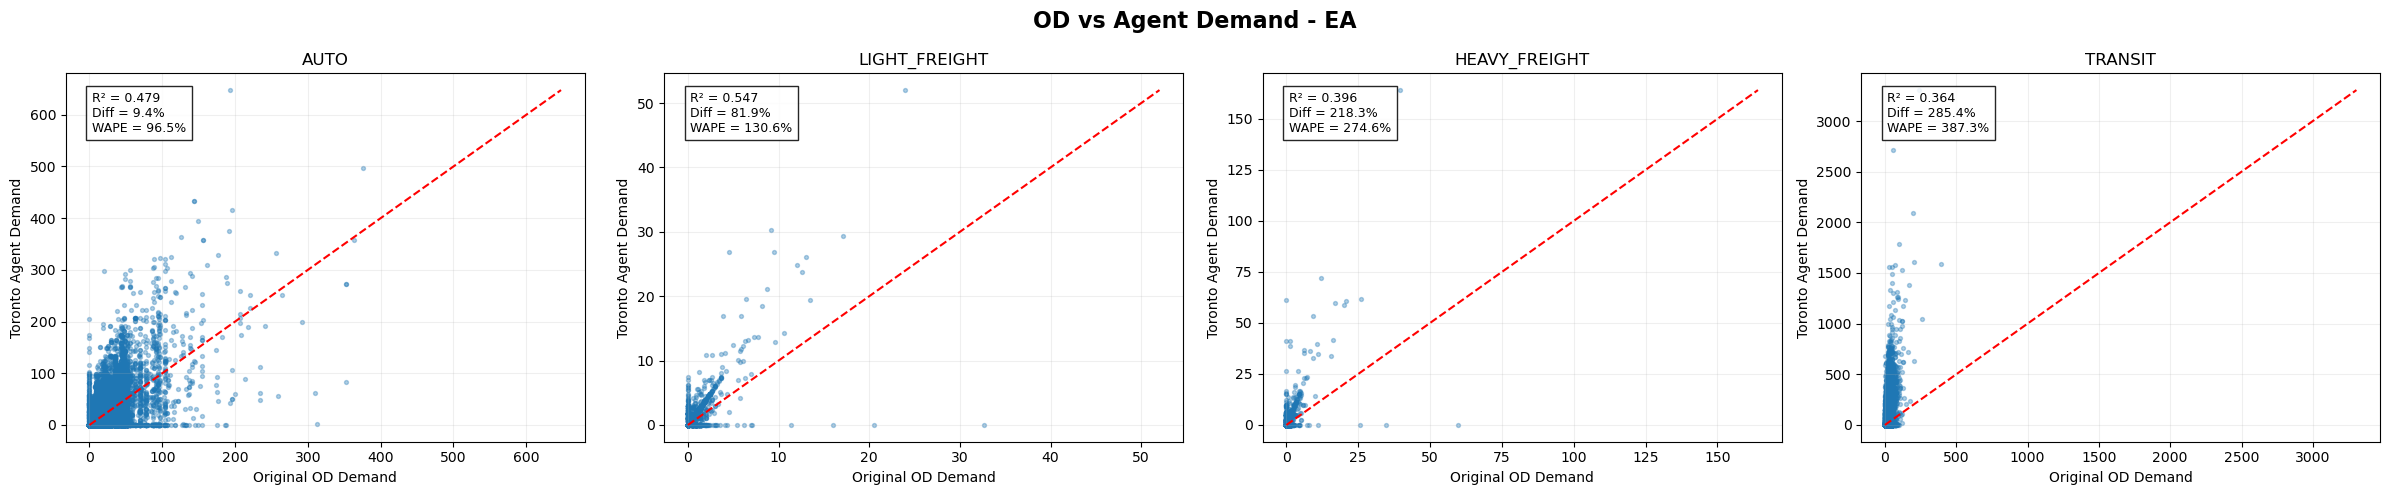

Processing PP - AUTO
Processing PP - LIGHT_FREIGHT
Processing PP - HEAVY_FREIGHT
Processing PP - TRANSIT


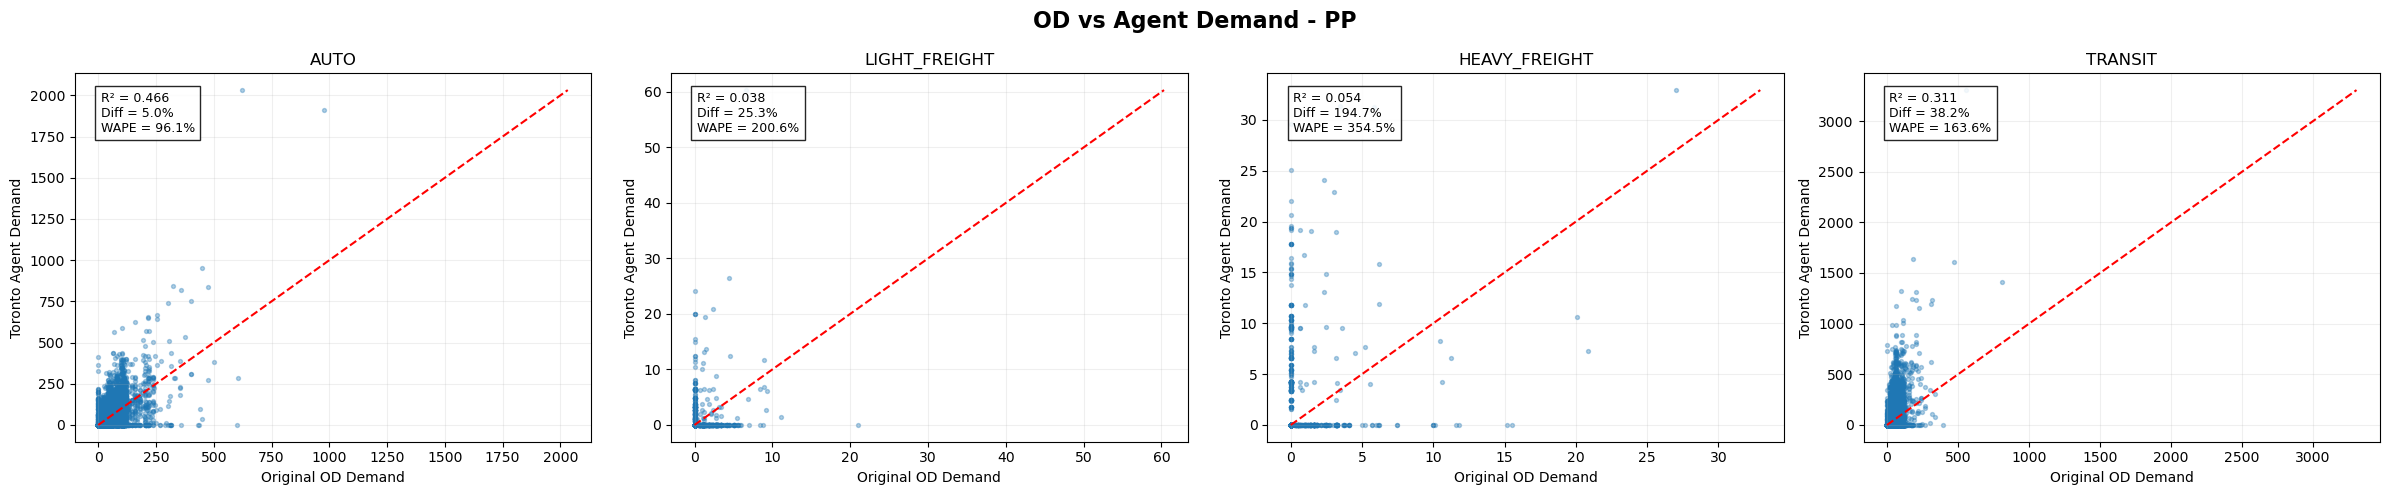

Processing LN - AUTO
Processing LN - TRANSIT


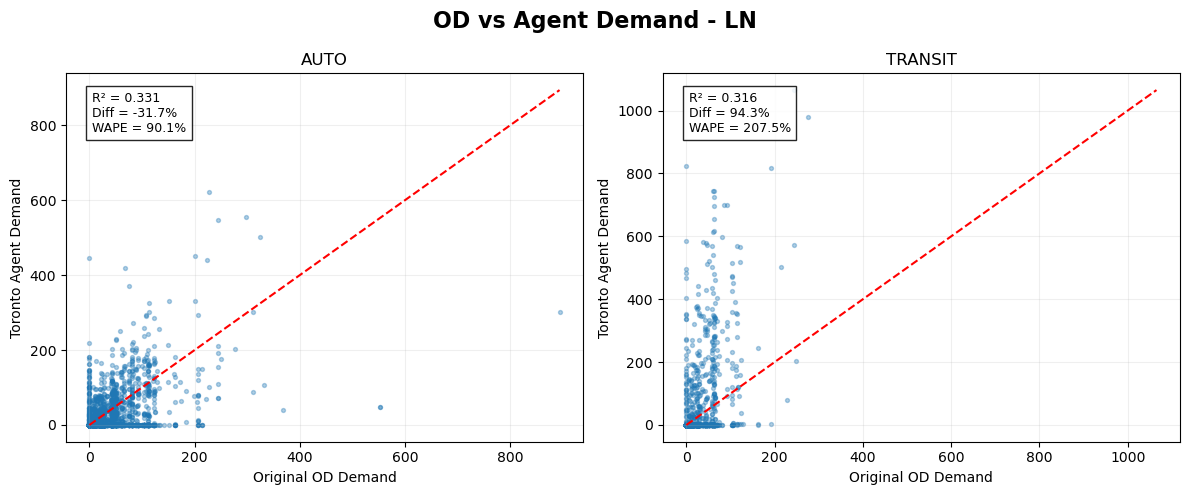

In [29]:
all_metrics = []

for period, modes in matrix_files.items():

    fig, axes = plt.subplots(
        1, len(modes),
        figsize=(6 * len(modes), 5),
        squeeze=False
    )

    axes = axes.flatten()

    for i, (mode, (od_file, agents_file)) in enumerate(modes.items()):

        print(f"Processing {period} - {mode}")

        # Read files
        od_raw = pd.read_csv(
            os.path.join(OD_DEMAND_FOLDER, od_file)
        )

        agents_raw = pd.read_csv(
            os.path.join(AGENTS_DEMAND_FOLDER, agents_file)
        )

        # Prepare matrices
        od = prepare_demand_od(od_raw)
        agents = prepare_demand_agents(agents_raw)

        # Compare
        comparison = compare_demand(od, agents)

        # Metrics
        metrics = calculate_metrics(comparison)
        metrics["Period"] = period
        metrics["Mode"] = mode

        all_metrics.append(metrics)

        # Plot on corresponding subplot
        plot_od_scatter(
            comparison,
            ax=axes[i],
            title=mode
        )

        # Free memory
        del od_raw, agents_raw, od, agents, comparison

    fig.suptitle(
        f"OD vs Agent Demand - {period}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    """plt.savefig(
        os.path.join(folder_results, f"OD_Comparison_{period}.png"),
        dpi=300,
        bbox_inches="tight"
    )"""

    plt.show()
    plt.close(fig)

In [33]:
metrics_summary.columns

Index(['Total_OD', 'Total_Agents', 'Difference', 'Pct_Difference',
       'R2_regression', 'R2_identity', 'Slope', 'Intercept', 'MAE', 'WAPE',
       'OD_Pairs', 'Only_OD', 'Only_Toronto', 'Period', 'Mode'],
      dtype='str')

In [34]:
metrics_summary = pd.DataFrame(all_metrics)

# Reorder columns
cols = [
    "Period", "Mode",
    "Total_OD", "Total_Agents",
    "Difference", "Pct_Difference",
    "R2_regression", "R2_identity",
    "Slope", "Intercept",
    "MAE", "WAPE",
    "OD_Pairs", "Only_OD", "Only_Toronto"
]

metrics_summary = metrics_summary[cols]

display(metrics_summary.round(3))

"""metrics_summary.to_csv(
    os.path.join(folder_results, "OD_Agents_Metrics.csv"),
    index=False
)"""

,Period,Mode,Total_OD,Total_Agents,Difference,Pct_Difference,R2_regression,R2_identity,Slope,Intercept,MAE,WAPE,OD_Pairs,Only_OD,Only_Toronto
0,EM,AUTO,"8,849.00","1,153.20","-7,695.80",-86.97,0.08,0.07,0.11,0.00,0.00,96.81,"4,431,025.00",226.00,0.00
1,EM,TRANSIT,"2,379.87",751.18,"-1,628.69",-68.44,0.01,-2.74,0.19,0.00,0.00,127.02,"4,431,025.00",95.00,0.00
2,AP,AUTO,"364,851.00","392,307.09","27,456.08",7.53,0.44,-0.15,0.95,0.01,0.08,100.57,"4,431,025.00","1,419.00",0.00
3,AP,LIGHT_FREIGHT,715.30,"1,811.12","1,095.81",153.19,0.60,-1.74,1.78,0.00,0.00,188.83,"4,431,025.00",53.00,0.00
4,AP,HEAVY_FREIGHT,555.15,"2,600.91","2,045.77",368.51,0.55,-9.39,2.90,0.00,0.00,414.16,"4,431,025.00",56.00,0.00
5,AP,TRANSIT,"265,301.13","543,854.66","278,553.53",105.00,0.31,-9.22,2.03,0.00,0.13,217.88,"4,431,025.00",327.00,0.00
6,LM,AUTO,"173,472.00","193,252.42","19,780.42",11.40,0.48,-0.06,0.99,0.01,0.04,97.12,"4,431,025.00",412.00,0.00
7,LM,LIGHT_FREIGHT,"1,671.48","3,367.59","1,696.11",101.47,0.53,-0.90,1.41,0.00,0.00,155.60,"4,431,025.00",192.00,0.00
8,LM,HEAVY_FREIGHT,"1,365.24","4,869.83","3,504.59",256.70,0.43,-6.15,2.10,0.00,0.00,320.81,"4,431,025.00",179.00,0.00
9,LM,TRANSIT,"101,904.09","197,239.33","95,335.24",93.55,0.31,-9.97,2.09,-0.00,0.05,209.96,"4,431,025.00",114.00,0.00


'metrics_summary.to_csv(\n    os.path.join(folder_results, "OD_Agents_Metrics.csv"),\n    index=False\n)'

Total_OD           364,851.00
Total_Agents       392,307.09
Difference          27,456.09
Pct_Difference           7.53
R2_regression            0.44
R2_identity             -0.15
Slope                    0.95
Intercept                0.01
MAE                      0.08
WAPE                   100.57
OD_Pairs         4,431,025.00
Only_OD              1,419.00
Only_Toronto             0.00
dtype: float64

/var/folders/8s/00_wwq9j23b09mnd7gp105m00000gp/T/ipykernel_2310/2054373160.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


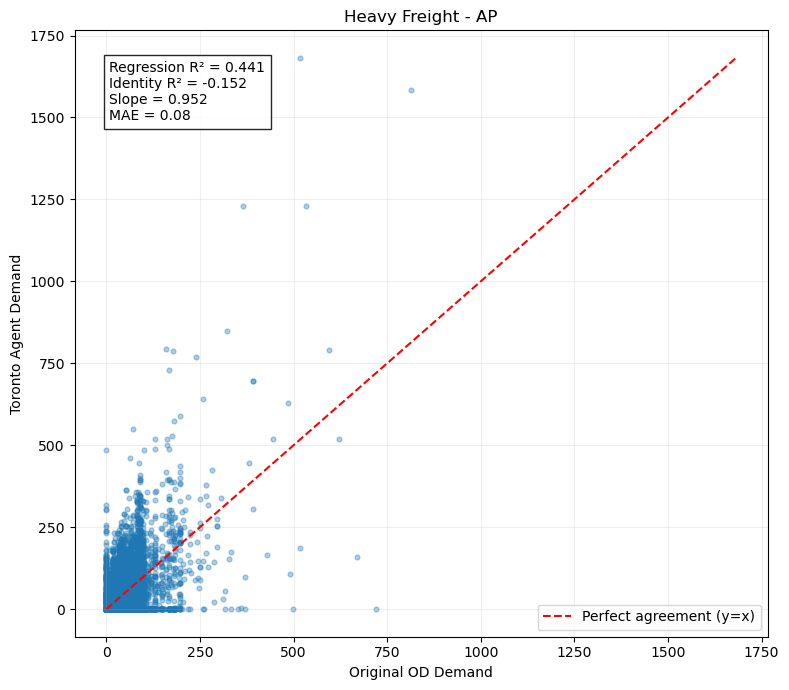

In [19]:
auto_ap_od = pd.read_csv(os.path.join(OD_DEMAND_FOLDER, "matriz_VP_AP.csv"))
auto_ap_agents = pd.read_csv(os.path.join(AGENTS_DEMAND_FOLDER, "AutoAP.mtx.csv"))

od_original = prepare_demand_od(auto_ap_od)
od_toronto = prepare_demand_agents(auto_ap_agents)

comparison = compare_demand(od_original, od_toronto)

metrics = calculate_metrics(comparison)

display(metrics)

plot_od_scatter(
    comparison,
    title="Heavy Freight - AP"
)

In [13]:
comparison

,Origin,Destination,Demand_OD,Demand_Agents,Difference,Abs_Difference,OD_Status
0,1,1,0.000000,0.0,0.000000,0.000000,Zero
1,1,2,0.000000,0.0,0.000000,0.000000,Zero
2,1,3,0.000000,0.0,0.000000,0.000000,Zero
3,1,4,0.000000,0.0,0.000000,0.000000,Zero
4,1,5,0.000000,0.0,0.000000,0.000000,Zero
...,...,...,...,...,...,...,...
4431020,10009,10005,0.000000,0.0,0.000000,0.000000,Zero
4431021,10009,10006,0.000000,0.0,0.000000,0.000000,Zero
4431022,10009,10007,0.000000,0.0,0.000000,0.000000,Zero
4431023,10009,10008,0.000000,0.0,0.000000,0.000000,Zero
